In [15]:
from __future__ import annotations

import importlib.util
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. PATH SETUP
# ==========================================

root = Path.cwd()

power_budget_file = root / "Basic PB Calculator.py"

csv_cases = {
    "PULSEPowerMinE": {
        "filepath": root / "PULSEPowerMinE.csv",
        "generation_column": "MinTotalPower",
    },
    "PULSEPowerMaxE": {
        "filepath": root / "PULSEPowerMaxE.csv",
        "generation_column": "MaxTotalPower", 
    },
}

print(root)
print(power_budget_file.exists())

for case_name, case_info in csv_cases.items():
    print(case_name, case_info["filepath"].exists())

C:\Users\Jeongwon Lee\new_new_PULSE_A_PB_calc
True
PULSEPowerMinE True
PULSEPowerMaxE True


In [16]:
# ==========================================
# 1. LOAD BASIC PB CALCULATOR
# ==========================================

def load_power_budget_calculator():
    """
    Import PowerBudgetCalculator from Basic PB Calculator.py.
    """

    spec = importlib.util.spec_from_file_location(
        "basic_pb",
        power_budget_file
    )

    module = importlib.util.module_from_spec(spec)

    old_stdout = sys.stdout

    # Run the Basic PB Calculator file
    try:
        sys.stdout = open(os.devnull, "w")
        spec.loader.exec_module(module)
    finally:
        sys.stdout.close()
        sys.stdout = old_stdout
        # Restores normal print output
    return module.PowerBudgetCalculator


def get_state_powers():
    """
    Gets spacecraft power draw values from Basic PB Calculator.py.

    Units:
    Watts = Wh per hour
    """
    # Dictionary of satellite's mode powers
    PowerBudgetCalculator = load_power_budget_calculator()
    calc = PowerBudgetCalculator()

    state_powers = {
        "No Control": calc.calculate_watts("No Control"),
        "Detumble": calc.calculate_watts("Detumble"),
        "Sun-Pointing": calc.calculate_watts("Sun-Pointing"),
        "Pointing Away": calc.calculate_watts("Pointing Away"),
        "RF Pass": calc.calculate_watts("RF Pass"),
        "Payload - Calibration": calc.calculate_watts("Payload - Calibration"),
        "Payload - Acquisition": calc.calculate_watts("Payload - Acquisition"),
    }

    return state_powers

In [17]:
PowerBudgetCalculator = load_power_budget_calculator()
calc = PowerBudgetCalculator()

print(calc.calculate_watts("Sun-Pointing"))
print(calc.calculate_watts("Payload - Acquisition"))

state_powers = get_state_powers()
print(state_powers)
print(state_powers["Sun-Pointing"])

5.2
16.35
{'No Control': 0.54, 'Detumble': 5.01, 'Sun-Pointing': 5.2, 'Pointing Away': 5.2, 'RF Pass': 5.98, 'Payload - Calibration': 14.59, 'Payload - Acquisition': 16.35}
5.2


In [18]:
# ==========================================
# 2. READ CSV POWER FILE
# ==========================================

def read_csv_power_file(filepath):
    """
    Read PULSEPowerMinE and PULSEPowerMaxE using NumPy.

    Expected columns:
    PULSE.ElapsedTime
    PULSE.InShadow
    PULSE.OrbitNumberBounded
    MaxTotalPower
    MinTotalPower
    """

    data = np.loadtxt(
        filepath,
        skiprows=3
    )
    """
    We skip the first 3 rows.
    row 1: blank line
    row 2: column names
    row 3: units
    row 4+: data
    """

    csv_data = {
        "elapsed_days": data[:, 0],
        "in_shadow": data[:, 1].astype(int),
        "orbit_number": data[:, 2].astype(int),
        "MaxTotalPower": data[:, 3],
        "MinTotalPower": data[:, 4],
    }

    return csv_data

In [19]:
# ==========================================
# 3. COMPUTE REAL CSV TIMING
# ==========================================

def add_time_columns(csv_data):
    """
    Convert elapsed days into hours/minutes and calculate timestep duration.
    """

    elapsed_days = csv_data["elapsed_days"]

    elapsed_hours = elapsed_days * 24.0
    elapsed_minutes = elapsed_days * 24.0 * 60.0

    dt_hours = np.zeros(len(elapsed_hours))
    dt_hours[:-1] = elapsed_hours[1:] - elapsed_hours[:-1]
    dt_hours[-1] = dt_hours[-2]

    dt_minutes = dt_hours * 60.0

    csv_data["elapsed_hours"] = elapsed_hours
    csv_data["elapsed_minutes"] = elapsed_minutes
    csv_data["dt_hours"] = dt_hours
    csv_data["dt_minutes"] = dt_minutes

    return csv_data

In [20]:
csv_data = read_csv_power_file("PULSEPowerMinE.csv")
csv_data = add_time_columns(csv_data)

print(csv_data["elapsed_minutes"][:5])
print(csv_data["dt_minutes"][:5])
print(np.mean(csv_data["dt_minutes"][:100]))

[0.       0.499968 0.999936 1.500048 2.000016]
[0.499968 0.499968 0.500112 0.499968 0.499968]
0.92666736


In [21]:
csv_data = read_csv_power_file("PULSEPowerMaxE.csv")
csv_data = add_time_columns(csv_data)

print(csv_data["elapsed_minutes"][:5])
print(csv_data["dt_minutes"][:5])
print(np.mean(csv_data["dt_minutes"][:100]))

[0.       0.999936 2.000016 2.999952 4.000032]
[0.999936 1.00008  0.999936 1.00008  0.999936]
0.99999936


In [22]:
print("Min dt:", np.min(csv_data["dt_minutes"]))
print("Max dt:", np.max(csv_data["dt_minutes"]))
print("Mean dt:", np.mean(csv_data["dt_minutes"]))

Min dt: 0.9999359997891588
Max dt: 1.0000800002308097
Mean dt: 1.0000000001369862


In [23]:
# ==========================================
# 4. COMPUTE CSV GENERATION
# ==========================================

def add_generation_column(csv_data, generation_column):
    """
    Convert cumulative CSV power/energy column into per-timestep generation Wh.
    """

    # This converts cumulative energy into timestep generation
    cumulative_energy = csv_data[generation_column]

    generation_wh = np.zeros(len(cumulative_energy))
    generation_wh[1:] = cumulative_energy[1:] - cumulative_energy[:-1]

    generation_wh = np.clip(generation_wh, 0.0, None)

    csv_data["generation_wh"] = generation_wh

    return csv_data

In [24]:
csv_data = add_generation_column(csv_data, "MinTotalPower")

print(csv_data["generation_wh"][:20])
print("Total generation:", np.sum(csv_data["generation_wh"]))

[0.        0.1327928 0.2260225 0.2825715 0.3213924 0.3425331 0.3572003
 0.3654481 0.3702124 0.3729878 0.1247291 0.        0.        0.
 0.        0.        0.        0.        0.        0.       ]
Total generation: 249866.8121246


In [25]:
# ==========================================
# 5. CHOOSE SPACECRAFT STATE
# ==========================================

def choose_spacecraft_state(
    orbit_number,
    in_shadow,
    minute_in_orbit,
):
    """
    Determine spacecraft operating state at each timestep.

    Current clean version:
    - eclipse: Sun-Pointing load
    - sunlight: Sun-Pointing load

    This is where RF pass, payload, calibration and off-pointing should be added later.

    if orbit number % 10 == 0 and in_shadow ==0:
        return "RF Pass"

    if in_shadow == 0 and 10 <= minute_in_orbit <= 20:
        return "Payload - Acquisition"
    """

    if in_shadow == 1:
        return "Sun-Pointing"

    if in_shadow == 0:
        return "Sun-Pointing"

    return "Sun-Pointing"

In [26]:
print(choose_spacecraft_state(1, 1, 5))
print(choose_spacecraft_state(1, 0, 50))

Sun-Pointing
Sun-Pointing


In [27]:
# ==========================================
# 6. RUN CSV-DRIVEN BATTERY SIMULATION
# ==========================================

def run_csv_mission_simulation(
    case_name,
    filepath,
    generation_column,
    battery_capacity_wh=40.0,
    initial_soc_fraction=0.95,
    max_soc_fraction=0.95,
):
    """
    Run battery simulation directly from CSV data.

    No fixed 90-min assumption.
    No fixed 55/35 sunlight/eclipse assumption.
    Uses actual CSV orbit timing and shadow timing.
    """

    state_powers = get_state_powers()

    csv_data = read_csv_power_file(filepath)
    csv_data = add_time_columns(csv_data)
    csv_data = add_generation_column(csv_data, generation_column)

    elapsed_minutes = csv_data["elapsed_minutes"]
    orbit_number = csv_data["orbit_number"]
    in_shadow = csv_data["in_shadow"]
    dt_hours = csv_data["dt_hours"]
    generation_wh = csv_data["generation_wh"]

    soc_wh = np.zeros(len(elapsed_minutes))
    soc_percent = np.zeros(len(elapsed_minutes))
    consumption_wh = np.zeros(len(elapsed_minutes))
    power_draw_w = np.zeros(len(elapsed_minutes))
    state_history = []

    soc = battery_capacity_wh * initial_soc_fraction
    max_soc = battery_capacity_wh * max_soc_fraction

    unique_orbits = np.unique(orbit_number)

    orbit_start_minutes = {}

    for orbit in unique_orbits:
        first_index = np.where(orbit_number == orbit)[0][0]
        orbit_start_minutes[orbit] = elapsed_minutes[first_index]

    for i in range(len(elapsed_minutes)):

        current_orbit = orbit_number[i]
        current_shadow = in_shadow[i]

        minute_in_orbit = (
            elapsed_minutes[i] - orbit_start_minutes[current_orbit]
        )

        state_name = choose_spacecraft_state(
            orbit_number = current_orbit,
            in_shadow = current_shadow,
            minute_in_orbit = minute_in_orbit,
        )

        state_history.append(state_name)

        current_power_w = state_powers[state_name]

        power_draw_w[i] = current_power_w
        consumption_wh[i] = current_power_w * dt_hours[i]

        net_wh = generation_wh[i] - consumption_wh[i]

        soc = soc + net_wh

        if soc > max_soc:
            soc = max_soc

        if soc < 0.0:
            soc = 0.0

        soc_wh[i] = soc
        soc_percent[i] = 100.0 * soc / battery_capacity_wh

    results = {
        "case_name": case_name,
        "elapsed_days": csv_data["elapsed_days"],
        "elapsed_hours": csv_data["elapsed_hours"],
        "elapsed_minutes": csv_data["elapsed_minutes"],
        "dt_hours": csv_data["dt_hours"],
        "dt_minutes": csv_data["dt_minutes"],
        "orbit_number": csv_data["orbit_number"],
        "in_shadow": csv_data["in_shadow"],
        "generation_wh": generation_wh,
        "consumption_wh": consumption_wh,
        "power_draw_w": power_draw_w,
        "soc_wh": soc_wh,
        "soc_percent": soc_percent,
        "state_history": np.array(state_history),
    }

    return results

In [28]:
results = run_csv_mission_simulation(
    case_name="PULSEPowerMinE",
    filepath=root / "PULSEPowerMinE.csv",
    generation_column="MinTotalPower",
)

print(results.keys())
print(results["soc_percent"][:10])
print("Minimum SoC:", np.min(results["soc_percent"]))
print("Maximum SoC:", np.max(results["soc_percent"]))

dict_keys(['case_name', 'elapsed_days', 'elapsed_hours', 'elapsed_minutes', 'dt_hours', 'dt_minutes', 'orbit_number', 'in_shadow', 'generation_wh', 'consumption_wh', 'power_draw_w', 'soc_wh', 'soc_percent', 'state_history'])
[94.8916736 94.7833472 94.6749896 94.5666632 94.4583368 94.3500104
 94.2416528 94.1333264 94.025     93.9166736]
Minimum SoC: 87.19999999992442
Maximum SoC: 95.0


In [29]:
# ==========================================
# 6. PER-ORBIT SUMMARY
# ==========================================

def summarize_by_orbit(results):
    """
    Build per-orbit summary table.

    Columns:
    orbit
    orbit_duration_min
    eclipse_min
    sunlight_min
    generation_wh
    consumption_wh
    min_power_w
    max_power_w
    mean_power_w
    min_soc_percent
    max_soc_percent
    final_soc_percent
    """

    orbit_number = results["orbit_number"]
    unique_orbits = np.unique(orbit_number)

    summary_rows = []

    for orbit in unique_orbits:

        indices = np.where(orbit_number == orbit)[0]

        start_index = indices[0]
        end_index = indices[-1]

        orbit_start_min = results["elapsed_minutes"][start_index]
        orbit_end_min = results["elapsed_minutes"][end_index]

        orbit_duration_min = np.sum(results["dt_minutes"][indices])

        eclipse_indices = indices[results["in_shadow"][indices] == 1]
        sunlight_indices = indices[results["in_shadow"][indices] == 0]

        eclipse_min = np.sum(results["dt_minutes"][eclipse_indices])
        sunlight_min = np.sum(results["dt_minutes"][sunlight_indices])

        generation_wh = np.sum(results["generation_wh"][indices])
        consumption_wh = np.sum(results["consumption_wh"][indices])

        min_power_w = np.min(results["power_draw_w"][indices])
        max_power_w = np.max(results["power_draw_w"][indices])
        mean_power_w = np.mean(results["power_draw_w"][indices])

        min_soc_percent = np.min(results["soc_percent"][indices])
        max_soc_percent = np.max(results["soc_percent"][indices])
        final_soc_percent = results["soc_percent"][end_index]

        row = [
            orbit,
            orbit_duration_min,
            eclipse_min,
            sunlight_min,
            generation_wh,
            consumption_wh,
            min_power_w,
            max_power_w,
            mean_power_w,
            min_soc_percent,
            max_soc_percent,
            final_soc_percent,
        ]

        summary_rows.append(row)

    return np.array(summary_rows)

In [30]:
orbit_summary = summarize_by_orbit(results)

print(orbit_summary.shape)
print(orbit_summary[:5])

(11270, 12)
[[ 1.         11.666736    7.666704    4.000032    0.64881     1.01111712
   5.2         5.2         5.2        93.175142   94.8916736  94.0942322 ]
 [ 2.         92.999952   30.000096   62.999856   20.1757836   8.05999584
   5.2         5.2         5.2        88.6347257  95.         90.14069885]
 [ 3.         94.000032   29.999952   64.00008    20.6980095   8.14666944
   5.2         5.2         5.2        88.7166632  95.         90.54493885]
 [ 4.         92.999952   30.000096   62.999856   20.3207196   8.05999584
   5.2         5.2         5.2        88.4999792  95.         90.14059085]
 [ 5.         92.999952   29.999952   63.         20.3197757   8.05999584
   5.2         5.2         5.2        88.7166632  95.         89.95302535]]


In [31]:
print(orbit_summary[:10, 1])

[11.666736 92.999952 94.000032 92.999952 92.999952 94.000032 92.999952
 93.000096 92.999952 94.000032]


In [32]:
print(orbit_summary[:10, 2])
print(orbit_summary[:10, 3])

[ 7.666704 30.000096 29.999952 30.000096 29.999952 31.000032 29.999952
 31.000032 29.999952 30.000096]
[ 4.000032 62.999856 64.00008  62.999856 63.       63.       63.
 62.000064 63.       63.999936]


In [33]:
print("Orbit duration:")
print(orbit_summary[:10, 1])

print("Eclipse + sunlight:")
print(orbit_summary[:10, 2] + orbit_summary[:10, 3])

print("Difference:")
print(orbit_summary[:10, 1] - (orbit_summary[:10, 2] + orbit_summary[:10, 3]))

Orbit duration:
[11.666736 92.999952 94.000032 92.999952 92.999952 94.000032 92.999952
 93.000096 92.999952 94.000032]
Eclipse + sunlight:
[11.666736 92.999952 94.000032 92.999952 92.999952 94.000032 92.999952
 93.000096 92.999952 94.000032]
Difference:
[-1.77635684e-15  0.00000000e+00  0.00000000e+00  0.00000000e+00
 -1.42108547e-14  1.42108547e-14  0.00000000e+00  0.00000000e+00
  1.42108547e-14 -1.42108547e-14]


In [34]:
# ==========================================
# 8. SAVE SUMMARY
# ==========================================

def save_orbit_summary(case_name, orbit_summary):
    """
    Save per-orbit summary to CSV.
    """

    header = (
        "orbit,"
        "orbit_duration_min,"
        "eclipse_min,"
        "sunlight_min,"
        "generation_wh,"
        "consumption_wh,"
        "min_power_w,"
        "max_power_w,"
        "mean_power_w,"
        "min_soc_percent,"
        "max_soc_percent,"
        "final_soc_percent"
    )

    output_file = root / f"{case_name}_orbit_summary.csv"

    np.savetxt(
        output_file,
        orbit_summary,
        delimiter=",",
        header=header,
        comments="",
        fmt="%.6f"
    )

    return output_file

In [35]:
output_file = save_orbit_summary("PULSEPowerMinE", orbit_summary)
print(output_file)
print(output_file.exists())

C:\Users\Jeongwon Lee\new_new_PULSE_A_PB_calc\PULSEPowerMinE_orbit_summary.csv
True


In [36]:
# ==========================================
# 9. PLOTS
# ==========================================

def plot_soc(results):
    """
    Plot battery SoC over elapsed time.
    """

    plt.figure(figsize=(10, 5))
    plt.plot(
        results["elapsed_hours"],
        results["soc_percent"],
        label=results["case_name"]
    )
    plt.xlabel("Elapsed Time (hours)")
    plt.ylabel("Battery SoC (%)")
    plt.title(f"Battery SoC: {results['case_name']}")
    plt.grid(True)
    plt.legend()
    plt.show()


def plot_generation_vs_consumption(results):
    """
    Plot timestep generation and consumption.
    """

    plt.figure(figsize=(10, 5))
    plt.plot(
        results["elapsed_hours"],
        results["generation_wh"],
        label="Generation Wh"
    )
    plt.plot(
        results["elapsed_hours"],
        results["consumption_wh"],
        label="Consumption Wh"
    )
    plt.xlabel("Elapsed Time (hours)")
    plt.ylabel("Energy per timestep (Wh)")
    plt.title(f"Generation vs Consumption: {results['case_name']}")
    plt.grid(True)
    plt.legend()
    plt.show()


def plot_orbit_timing(case_name, orbit_summary):
    """
    Plot real orbit duration, eclipse duration, and sunlight duration.
    """

    orbit = orbit_summary[:, 0]
    orbit_duration = orbit_summary[:, 1]
    eclipse_min = orbit_summary[:, 2]
    sunlight_min = orbit_summary[:, 3]

    plt.figure(figsize=(10, 5))
    plt.plot(orbit, orbit_duration, label="Orbit duration")
    plt.plot(orbit, eclipse_min, label="Eclipse duration")
    plt.plot(orbit, sunlight_min, label="Sunlight duration")
    plt.xlabel("Orbit Number")
    plt.ylabel("Minutes")
    plt.title(f"CSV Orbit Timing: {case_name}")
    plt.grid(True)
    plt.legend()
    plt.show()

In [37]:
# ==========================================
# 10. RUN ALL CASES
# ==========================================

def run_all_cases():
    """
    Run MinE and MaxE cases if their CSV files exist.
    """

    all_results = {}
    all_summaries = {}

    for case_name, case_info in csv_cases.items():

        filepath = case_info["filepath"]
        generation_column = case_info["generation_column"]

        if not filepath.exists():
            print(f"Skipping {case_name}: file not found at {filepath}")
            continue

        print()
        print("=" * 60)
        print(f"Running case: {case_name}")
        print("=" * 60)

        results = run_csv_mission_simulation(
            case_name=case_name,
            filepath=filepath,
            generation_column=generation_column,
            battery_capacity_wh=40.0,
            initial_soc_fraction=0.95,
            max_soc_fraction=0.95,
        )

        orbit_summary = summarize_by_orbit(results)

        output_file = save_orbit_summary(
            case_name=case_name,
            orbit_summary=orbit_summary
        )

        all_results[case_name] = results
        all_summaries[case_name] = orbit_summary

        print("First 10 orbit summary rows:")
        print(
            "orbit | duration | eclipse | sunlight | generation | "
            "consumption | min_power | max_power | mean_power | "
            "min_soc | max_soc | final_soc"
        )
        print(orbit_summary[:10])

        print()
        print(f"Saved summary to: {output_file}")
        print(f"Minimum SoC: {np.min(results['soc_percent']):.2f}%")
        print(f"Maximum SoC: {np.max(results['soc_percent']):.2f}%")
        print(f"Final SoC: {results['soc_percent'][-1]:.2f}%")

        plot_soc(results)
        plot_generation_vs_consumption(results)
        plot_orbit_timing(case_name, orbit_summary)

    return all_results, all_summaries


Running case: PULSEPowerMinE
First 10 orbit summary rows:
orbit | duration | eclipse | sunlight | generation | consumption | min_power | max_power | mean_power | min_soc | max_soc | final_soc
[[ 1.         11.666736    7.666704    4.000032    0.64881     1.01111712
   5.2         5.2         5.2        93.175142   94.8916736  94.0942322 ]
 [ 2.         92.999952   30.000096   62.999856   20.1757836   8.05999584
   5.2         5.2         5.2        88.6347257  95.         90.14069885]
 [ 3.         94.000032   29.999952   64.00008    20.6980095   8.14666944
   5.2         5.2         5.2        88.7166632  95.         90.54493885]
 [ 4.         92.999952   30.000096   62.999856   20.3207196   8.05999584
   5.2         5.2         5.2        88.4999792  95.         90.14059085]
 [ 5.         92.999952   29.999952   63.         20.3197757   8.05999584
   5.2         5.2         5.2        88.7166632  95.         89.95302535]
 [ 6.         94.000032   31.000032   63.         20.5889945  

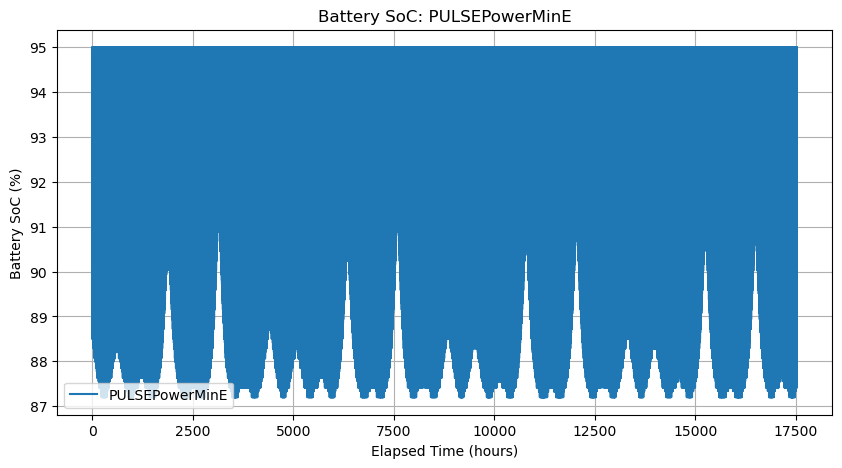

C:\Users\Jeongwon Lee\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


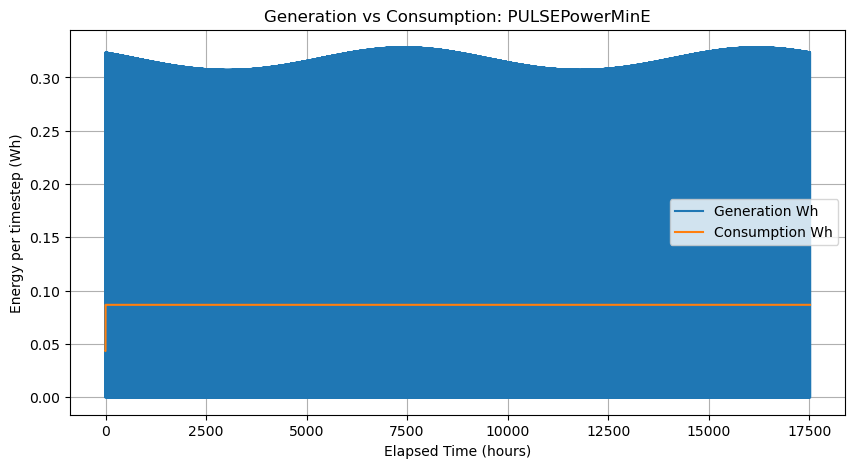

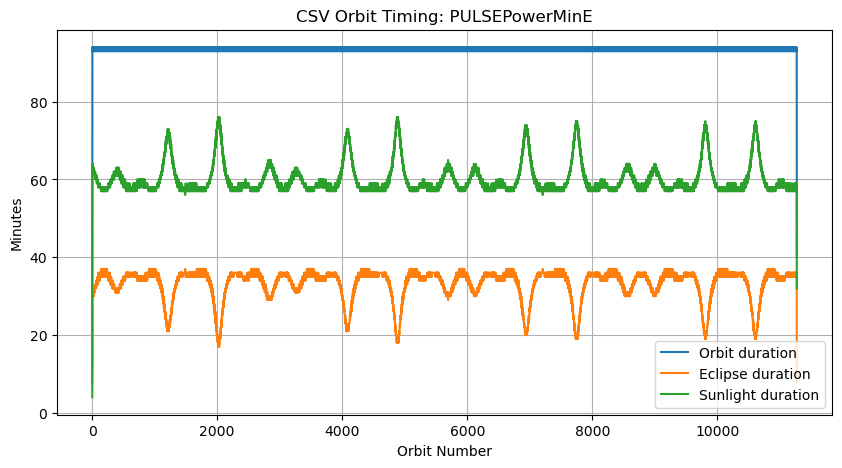


Running case: PULSEPowerMaxE
First 10 orbit summary rows:
orbit | duration | eclipse | sunlight | generation | consumption | min_power | max_power | mean_power | min_soc | max_soc | final_soc
[[ 1.         44.000064   30.000096   13.999968    4.3372183   3.81333888
   5.2         5.2         5.2        88.7166632  95.         91.29720085]
 [ 2.         92.999952   29.999952   63.         23.7832822   8.05999584
   5.2         5.2         5.2        88.6572747  95.         90.8386196 ]
 [ 3.         92.999952   29.999952   63.         23.7840782   8.05999584
   5.2         5.2         5.2        88.6573024  95.         90.6812333 ]
 [ 4.         93.000096   29.999952   63.000144   23.7830597   8.06000832
   5.2         5.2         5.2        88.7166632  95.         90.4259289 ]
 [ 5.         92.999952   30.000096   62.999856   23.7196006   8.05999584
   5.2         5.2         5.2        88.5000104  95.         89.95397085]
 [ 6.         94.000032   29.999952   64.00008    24.0954389  

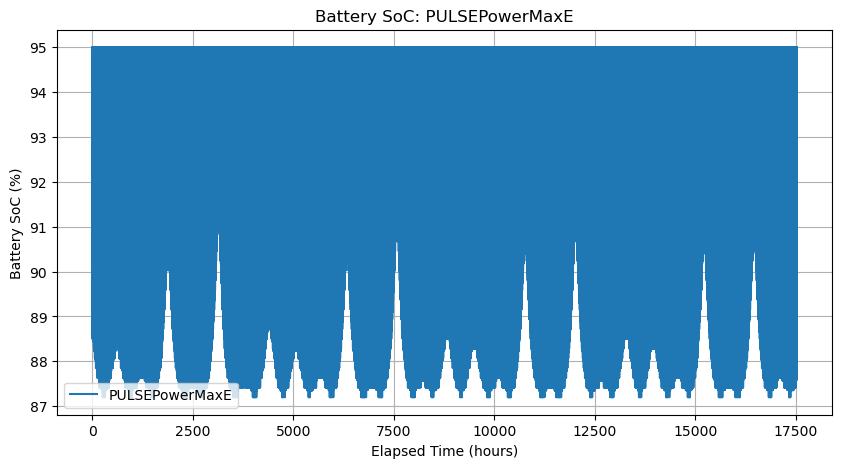

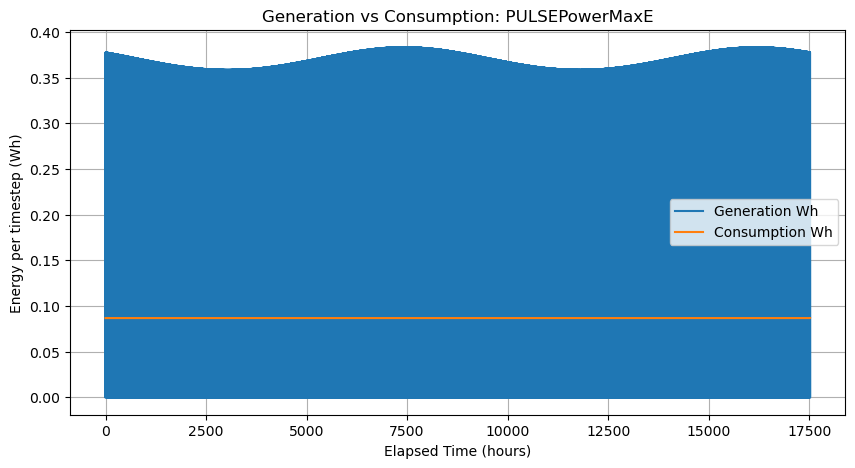

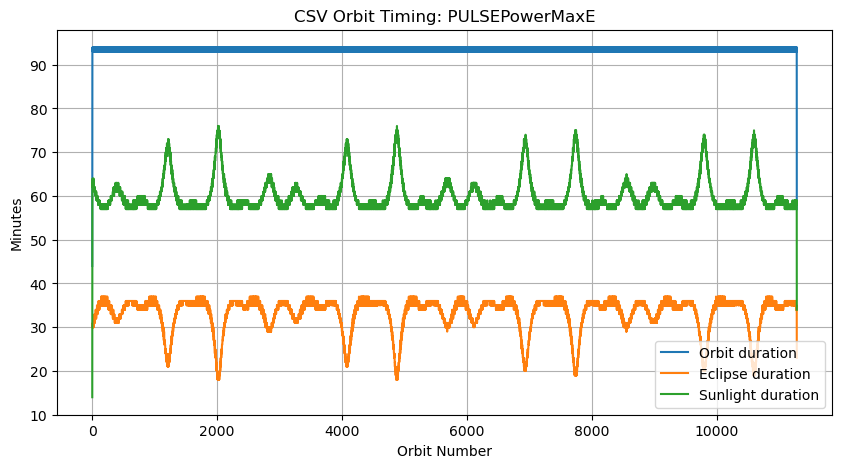

dict_keys(['PULSEPowerMinE', 'PULSEPowerMaxE'])
dict_keys(['PULSEPowerMinE', 'PULSEPowerMaxE'])


In [38]:
all_results, all_summaries = run_all_cases()
print(all_results.keys())
print(all_summaries.keys())

In [39]:
state_powers = get_state_powers()
print(state_powers)

csv_data = read_csv_power_file(root / "PULSEPowerMinE.csv")
csv_data = add_time_columns(csv_data)
csv_data = add_generation_column(csv_data, "MinTotalPower")

print("First elapsed minutes:", csv_data["elapsed_minutes"][:5])
print("First dt minutes:", csv_data["dt_minutes"][:5])
print("First shadow values:", csv_data["in_shadow"][:10])
print("First generation values:", csv_data["generation_wh"][:10])

{'No Control': 0.54, 'Detumble': 5.01, 'Sun-Pointing': 5.2, 'Pointing Away': 5.2, 'RF Pass': 5.98, 'Payload - Calibration': 14.59, 'Payload - Acquisition': 16.35}
First elapsed minutes: [0.       0.499968 0.999936 1.500048 2.000016]
First dt minutes: [0.499968 0.499968 0.500112 0.499968 0.499968]
First shadow values: [1 1 1 1 1 1 1 1 1 1]
First generation values: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [40]:
results = run_csv_mission_simulation(
    case_name="PULSEPowerMinE",
    filepath=root / "PULSEPowerMinE.csv",
    generation_column="MinTotalPower",
)

orbit_summary = summarize_by_orbit(results)

print(orbit_summary[:10])
print("Orbit durations:", orbit_summary[:10, 1])
print("Eclipse minutes:", orbit_summary[:10, 2])
print("Sunlight minutes:", orbit_summary[:10, 3])
print("Minimum SoC:", np.min(results["soc_percent"]))

[[ 1.         11.666736    7.666704    4.000032    0.64881     1.01111712
   5.2         5.2         5.2        93.175142   94.8916736  94.0942322 ]
 [ 2.         92.999952   30.000096   62.999856   20.1757836   8.05999584
   5.2         5.2         5.2        88.6347257  95.         90.14069885]
 [ 3.         94.000032   29.999952   64.00008    20.6980095   8.14666944
   5.2         5.2         5.2        88.7166632  95.         90.54493885]
 [ 4.         92.999952   30.000096   62.999856   20.3207196   8.05999584
   5.2         5.2         5.2        88.4999792  95.         90.14059085]
 [ 5.         92.999952   29.999952   63.         20.3197757   8.05999584
   5.2         5.2         5.2        88.7166632  95.         89.95302535]
 [ 6.         94.000032   31.000032   63.         20.5889945   8.14666944
   5.2         5.2         5.2        88.4999792  95.         90.14045185]
 [ 7.         92.999952   29.999952   63.         20.2646995   8.05999584
   5.2         5.2         5.2  

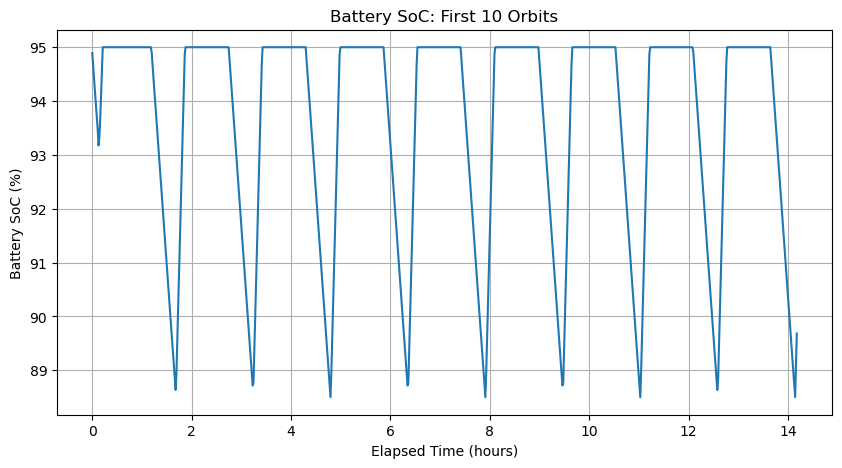

In [45]:
first_10_orbits = results["orbit_number"] <= 10

plt.figure(figsize=(10, 5))
plt.plot(
    results["elapsed_hours"][first_10_orbits],
    results["soc_percent"][first_10_orbits]
)
plt.xlabel("Elapsed Time (hours)")
plt.ylabel("Battery SoC (%)")
plt.title("Battery SoC: First 10 Orbits")
plt.grid(True)
plt.show()

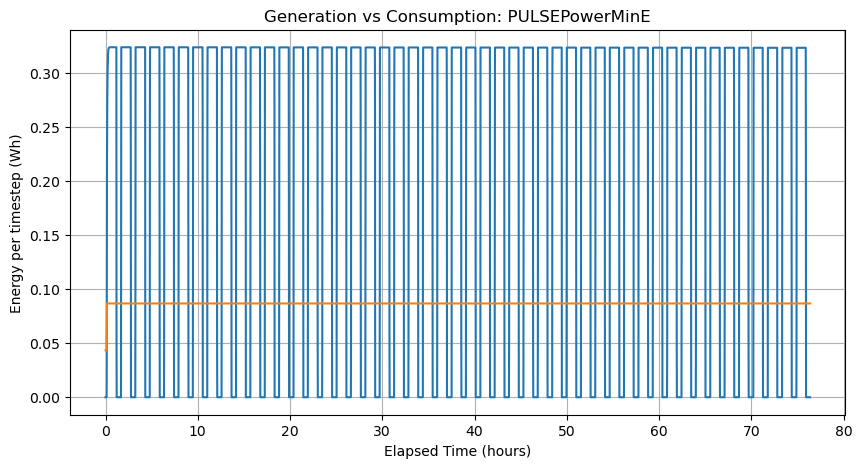

In [48]:
first_10_orbits = results["orbit_number"] <= 50

plt.figure(figsize=(10, 5))
plt.plot(
    results["elapsed_hours"][first_10_orbits],
    results["generation_wh"][first_10_orbits],
    label="Generation Wh"
)
plt.plot(
    results["elapsed_hours"][first_10_orbits],
    results["consumption_wh"][first_10_orbits],
    label="Consumption Wh"
)
plt.xlabel("Elapsed Time (hours)")
plt.ylabel("Energy per timestep (Wh)")
plt.title(f"Generation vs Consumption: {results['case_name']}")
plt.grid(True)
plt.show()

State powers from Basic PB Calculator:
{'No Control': 0.54, 'Detumble': 5.01, 'Sun-Pointing': 5.2, 'Pointing Away': 5.2, 'RF Pass': 5.98, 'Payload - Calibration': 14.59, 'Payload - Acquisition': 16.35}

Debug timestep check:
First elapsed minutes: [0.       0.499968 0.999936 1.500048 2.000016]
First dt minutes: [0.499968 0.499968 0.500112 0.499968 0.499968]
Average dt minutes: 0.92666736

Running case: PULSEPowerMinE
First 10 orbit summary rows:
orbit | duration | eclipse | sunlight | generation | consumption | min_power | max_power | mean_power | min_soc | max_soc | final_soc
[[ 1.         11.666736    7.666704    4.000032    0.64881     1.01111712
   5.2         5.2         5.2        93.175142   94.8916736  94.0942322 ]
 [ 2.         92.999952   30.000096   62.999856   20.1757836   8.05999584
   5.2         5.2         5.2        88.6347257  95.         90.14069885]
 [ 3.         94.000032   29.999952   64.00008    20.6980095   8.14666944
   5.2         5.2         5.2        88.716

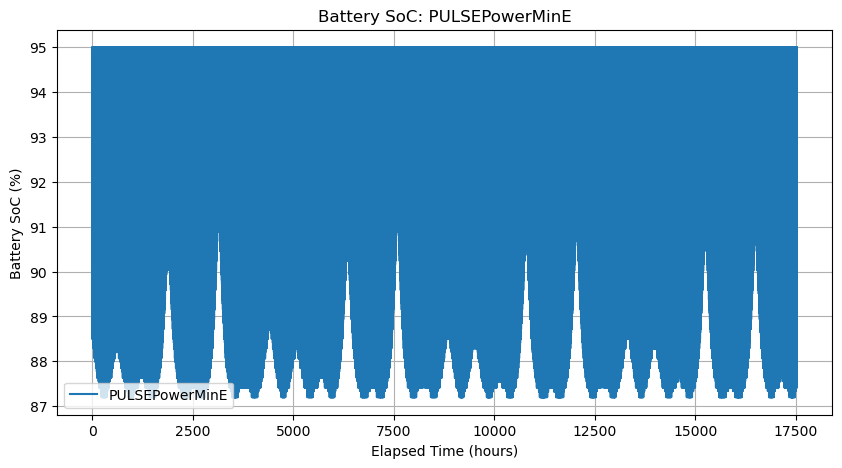

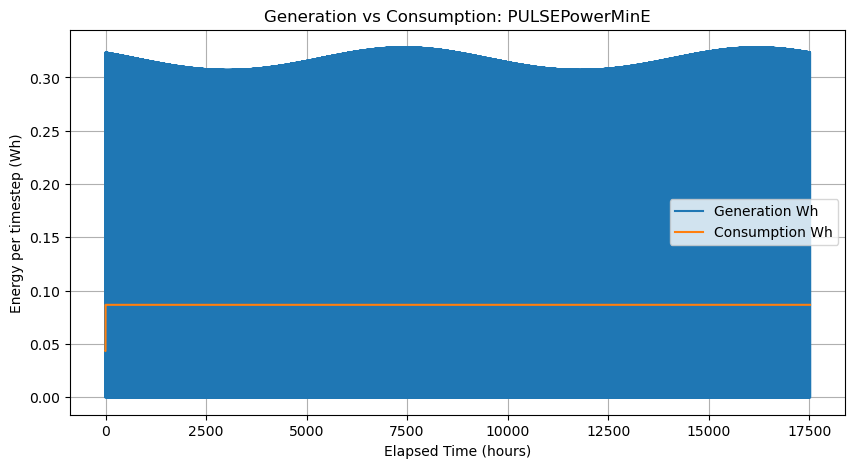

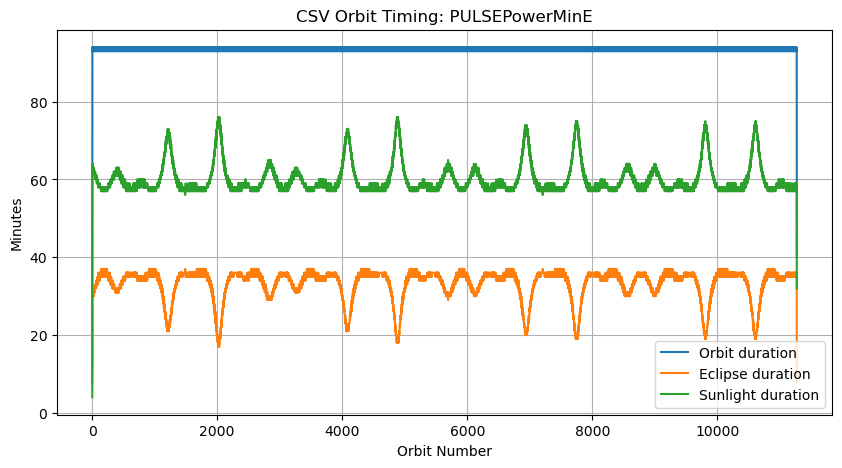


Running case: PULSEPowerMaxE
First 10 orbit summary rows:
orbit | duration | eclipse | sunlight | generation | consumption | min_power | max_power | mean_power | min_soc | max_soc | final_soc
[[ 1.         44.000064   30.000096   13.999968    4.3372183   3.81333888
   5.2         5.2         5.2        88.7166632  95.         91.29720085]
 [ 2.         92.999952   29.999952   63.         23.7832822   8.05999584
   5.2         5.2         5.2        88.6572747  95.         90.8386196 ]
 [ 3.         92.999952   29.999952   63.         23.7840782   8.05999584
   5.2         5.2         5.2        88.6573024  95.         90.6812333 ]
 [ 4.         93.000096   29.999952   63.000144   23.7830597   8.06000832
   5.2         5.2         5.2        88.7166632  95.         90.4259289 ]
 [ 5.         92.999952   30.000096   62.999856   23.7196006   8.05999584
   5.2         5.2         5.2        88.5000104  95.         89.95397085]
 [ 6.         94.000032   29.999952   64.00008    24.0954389  

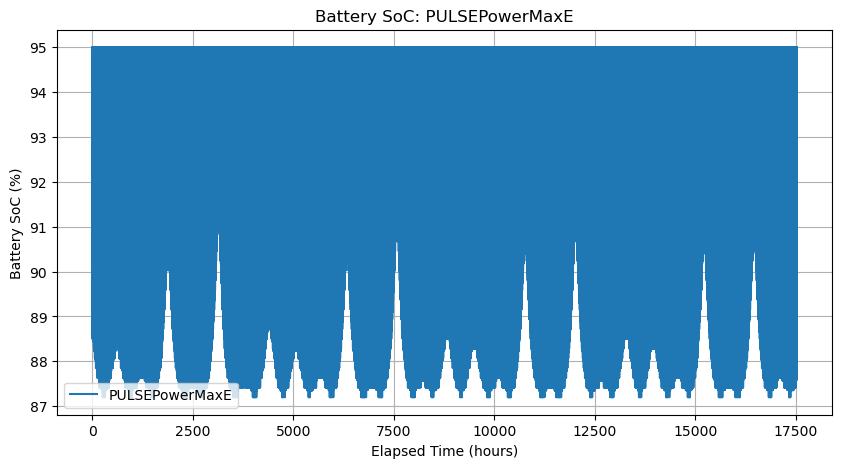

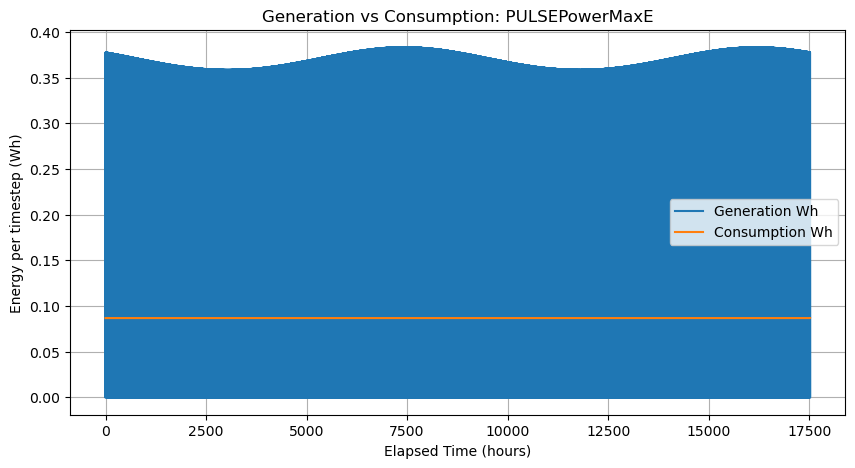

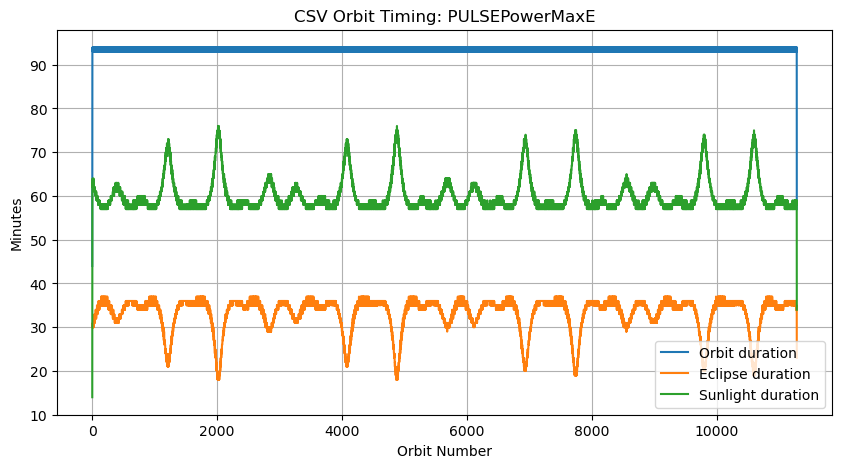

In [41]:
# ==========================================
# 11. EXECUTION
# ==========================================

if __name__ == "__main__":

    print("State powers from Basic PB Calculator:")
    print(get_state_powers())

    test_data = read_csv_power_file(root / "PULSEPowerMinE.csv")
    test_data = add_time_columns(test_data)

    print()
    print("Debug timestep check:")
    print("First elapsed minutes:", test_data["elapsed_minutes"][:5])
    print("First dt minutes:", test_data["dt_minutes"][:5])
    print("Average dt minutes:", np.mean(test_data["dt_minutes"][:100]))

    all_results, all_summaries = run_all_cases()